In [15]:
import pandas as pd

files = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
]

dfs = [pd.read_csv(f, encoding="latin1") for f in files]
full_df = pd.concat(dfs, ignore_index=True)

target_classes = ["BENIGN", "DDoS", "FTP-Patator", "SSH-Patator"]
full_df = full_df[full_df[" Label"].isin(target_classes)]

label_map = {
    "BENIGN": 0,
    "DDoS": 1,
    "FTP-Patator": 2,
    "SSH-Patator": 3
}

full_df[" Label"] = full_df[" Label"].map(label_map)
full_df = full_df.dropna()

print(full_df[" Label"].value_counts())

full_df.to_csv("processed_dataset.csv", index=False)

 Label
0    754348
1    128027
2      7938
3      2973
Name: count, dtype: int64


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix

df = pd.read_csv("processed_dataset.csv")
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("processed_dataset.csv")
print(df.shape)
print(df[" Label"].value_counts())

(955048, 79)
 Label
0.0    816108
1.0    128027
2.0      7938
3.0      2973
Name: count, dtype: int64


In [17]:
X = df.drop(columns=[" Label"])
y = df[" Label"]

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print(X.shape, y.shape)
print(X.isnull().sum().sum())

(955048, 78) (955048,)
0


In [18]:
import numpy as np

X = X.replace([np.inf, -np.inf], np.nan)

print(X.isnull().sum().sum())

X = X.fillna(X.median())

print(X.isnull().sum().sum())

0
0


In [22]:
print("NaNs in y before cleanup:", y.isnull().sum())

mask = y.notnull()
X = X[mask]
y = y[mask]

print("NaNs in y after cleanup:", y.isnull().sum())
print(X.shape, y.shape)

NaNs in y before cleanup: 2
NaNs in y after cleanup: 0
(955046, 78) (955046,)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(len(X_train), len(X_test))

764036 191010


In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_weighted",
        "recall": "recall_weighted",
        "f1": "f1_weighted"
    },
    n_jobs=-1
)

for i in range(5):
    print(f"Fold {i+1}: Acc={cv_results['test_accuracy'][i]:.4f} Prec={cv_results['test_precision'][i]:.4f} Rec={cv_results['test_recall'][i]:.4f} F1={cv_results['test_f1'][i]:.4f}")

print(cv_results['test_accuracy'].mean())
print(cv_results['test_precision'].mean())
print(cv_results['test_recall'].mean())
print(cv_results['test_f1'].mean())

Fold 1: Acc=0.9999 Prec=0.9999 Rec=0.9999 F1=0.9999
Fold 2: Acc=0.9999 Prec=0.9999 Rec=0.9999 F1=0.9999
Fold 3: Acc=0.9999 Prec=0.9999 Rec=0.9999 F1=0.9999
Fold 4: Acc=0.9999 Prec=0.9999 Rec=0.9999 F1=0.9999
Fold 5: Acc=0.9999 Prec=0.9999 Rec=0.9999 F1=0.9999
0.9999149254918457
0.9999149305523701
0.9999149254918457
0.9999148962573317


In [26]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [27]:
y_pred = model.predict(X_test)

train_pred = model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print(train_accuracy, test_accuracy, precision, recall, f1)

1.0 0.9999528820480603 0.9999528846459833 0.9999528820480603 0.9999528461053421


In [28]:
label_map = {
    0: "BENIGN",
    1: "DDoS",
    2: "FTP-Patator",
    3: "SSH-Patator"
}

present_labels = sorted(y_test.unique())
present_names = [label_map[i] for i in present_labels]

print(classification_report(
    y_test,
    y_pred,
    labels=present_labels,
    target_names=present_names
))

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    163222
        DDoS       1.00      1.00      1.00     25605
 FTP-Patator       1.00      1.00      1.00      1588
 SSH-Patator       1.00      0.99      1.00       595

    accuracy                           1.00    191010
   macro avg       1.00      1.00      1.00    191010
weighted avg       1.00      1.00      1.00    191010



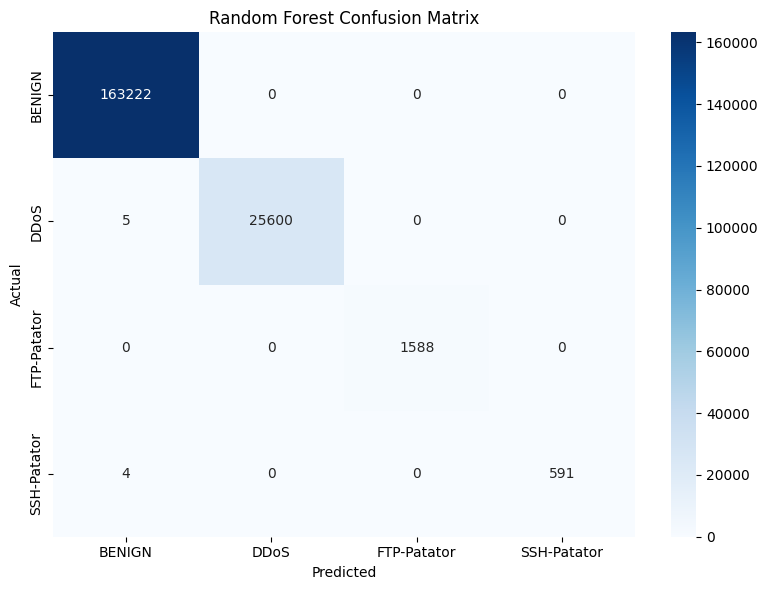

In [29]:
cm = confusion_matrix(y_test, y_pred, labels=present_labels)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=present_names,
    yticklabels=present_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig("rf_confusion_matrix.png")
plt.show()

                     Feature  Importance
0           Destination Port    0.131907
67   Init_Win_bytes_backward    0.060551
52       Average Packet Size    0.048787
8     Fwd Packet Length Mean    0.044646
54      Avg Bwd Segment Size    0.043260
39         Max Packet Length    0.042852
69      min_seg_size_forward    0.040021
42    Packet Length Variance    0.031398
53      Avg Fwd Segment Size    0.029069
10     Bwd Packet Length Max    0.026886
41         Packet Length Std    0.026184
9      Fwd Packet Length Std    0.025926
63         Subflow Fwd Bytes    0.025587
6      Fwd Packet Length Max    0.024574
40        Packet Length Mean    0.022911
35         Bwd Header Length    0.021863
14              Flow Bytes/s    0.021596
12    Bwd Packet Length Mean    0.019879
68          act_data_pkt_fwd    0.019098
37             Bwd Packets/s    0.018018


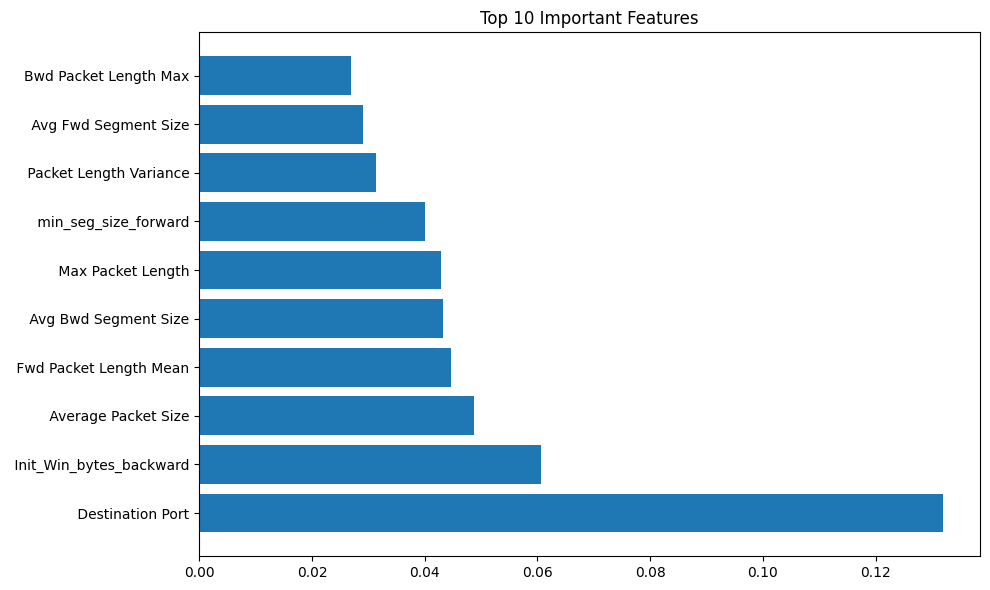

In [30]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print(feature_importance.head(20))

feature_importance.to_csv("rf_feature_importance.csv", index=False)

top10 = feature_importance.head(10)

plt.figure(figsize=(10,6))
plt.barh(top10["Feature"], top10["Importance"])
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.savefig("rf_feature_importance.png")
plt.show()

In [33]:
import joblib
joblib.dump(model, "random_forest_model.pkl")

result = pd.DataFrame({
    "Model": ["Random Forest"],
    "Training Accuracy": [train_accuracy],
    "Test Accuracy": [test_accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "Weighted F1 Score": [f1]
})

result.to_csv("random_forest_result.csv", index=False)

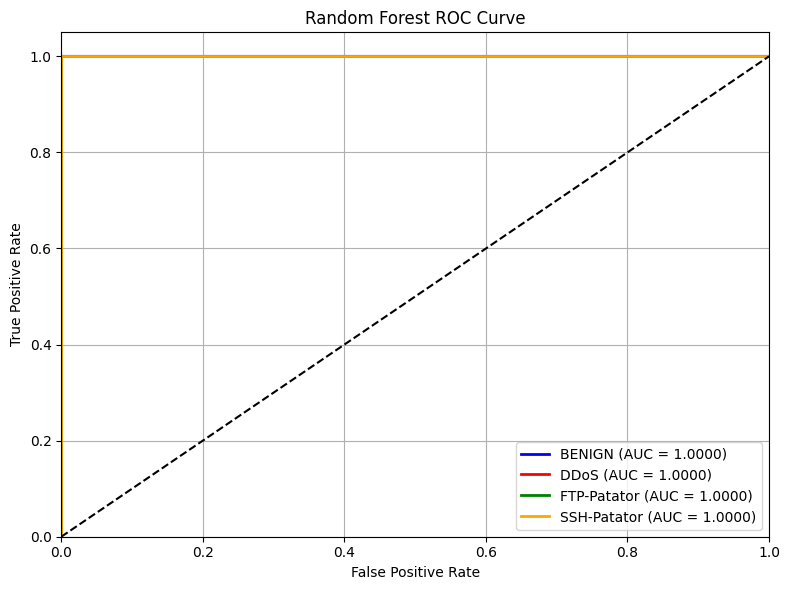

BENIGN : 1.000000
DDoS : 1.000000
FTP-Patator : 1.000000
SSH-Patator : 1.000000


In [34]:
model_classes = model.classes_
class_names = [label_map[c] for c in model_classes]

y_score = model.predict_proba(X_test)

y_test_bin = label_binarize(y_test, classes=model_classes)

n_classes = y_test_bin.shape[1]

fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8,6))

colors = cycle(["blue", "red", "green", "orange"])

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f"{class_names[i]} (AUC = {roc_auc[i]:.4f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig("rf_roc_curve.png")
plt.show()

for i in range(n_classes):
    print(f"{class_names[i]} : {roc_auc[i]:.6f}")

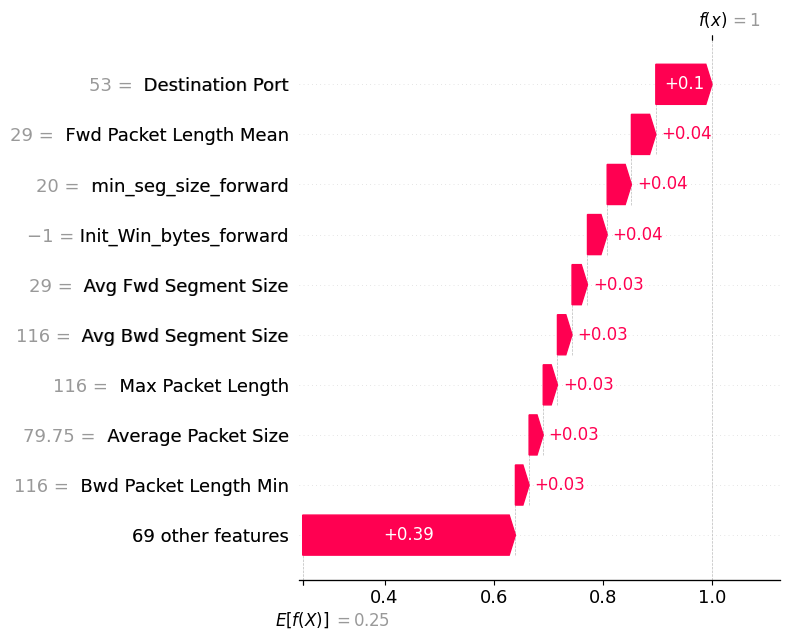

In [35]:
X_test_sample = X_test.sample(1000, random_state=42)

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test_sample)

if isinstance(shap_values, list):
    shap_list = shap_values
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_list = [shap_values[:, :, i] for i in range(shap_values.shape[2])]
else:
    shap_list = [shap_values]

for i, class_name in enumerate(class_names):
    plt.figure()
    shap.summary_plot(
        shap_list[i],
        X_test_sample,
        feature_names=X.columns,
        show=False
    )
    plt.title(f"SHAP Summary - {class_name}")
    plt.tight_layout()
    plt.savefig(f"shap_summary_{class_name}.png")
    plt.close()

plt.figure()

if len(shap_list) > 1:
    shap.summary_plot(
        shap_list,
        X_test_sample,
        feature_names=X.columns,
        class_names=class_names,
        show=False
    )
else:
    shap.summary_plot(
        shap_list[0],
        X_test_sample,
        feature_names=X.columns,
        show=False
    )

plt.tight_layout()
plt.savefig("shap_overall_importance.png")
plt.close()

explanation = explainer(X_test_sample)

sample_idx = 0

predicted_class = model.predict(X_test_sample.iloc[[sample_idx]])[0]

class_index = list(model_classes).index(predicted_class)

plt.figure()

if len(explanation.shape) == 3:
    shap.plots.waterfall(explanation[sample_idx, :, class_index], show=False)
else:
    shap.plots.waterfall(explanation[sample_idx], show=False)

plt.tight_layout()
plt.savefig("shap_waterfall_sample0.png")
plt.show()

In [36]:
print("Model classes (encoded):", model.classes_)
print("Model classes (names):", class_names)
print()

print("Type of shap_values:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of SHAP class outputs:", len(shap_values))
    for i, name in enumerate(class_names):
        print(f"Class {i} - {name}: shap array shape = {shap_values[i].shape}")

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    print("SHAP array shape:", shap_values.shape)
    print("Number of classes in SHAP output:", shap_values.shape[2])
    for i, name in enumerate(class_names):
        print(f"Class {i} - {name}: shap array shape = {shap_values[:,:,i].shape}")

else:
    print("SHAP output is single-class/2D — shape:", shap_values.shape)

Model classes (encoded): [0. 1. 2. 3.]
Model classes (names): ['BENIGN', 'DDoS', 'FTP-Patator', 'SSH-Patator']

Type of shap_values: <class 'numpy.ndarray'>
SHAP array shape: (1000, 78, 4)
Number of classes in SHAP output: 4
Class 0 - BENIGN: shap array shape = (1000, 78)
Class 1 - DDoS: shap array shape = (1000, 78)
Class 2 - FTP-Patator: shap array shape = (1000, 78)
Class 3 - SSH-Patator: shap array shape = (1000, 78)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


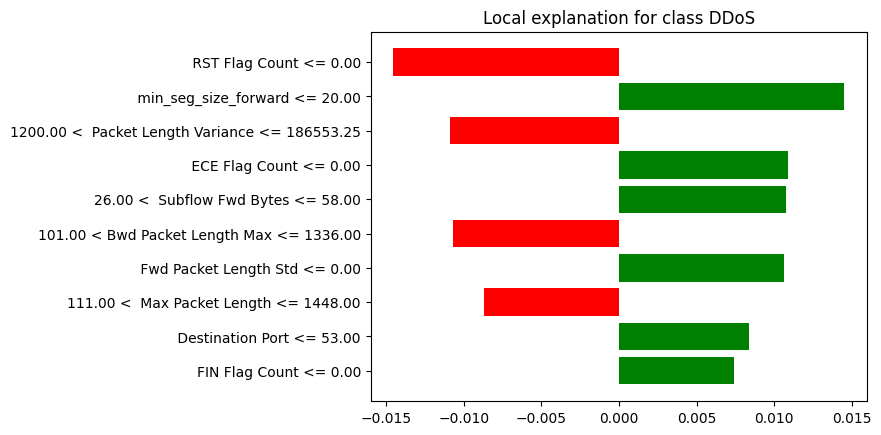

In [37]:
import lime
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=class_names,
    mode='classification'
)

exp = lime_explainer.explain_instance(
    data_row=X_test_sample.iloc[0].values,
    predict_fn=model.predict_proba,
    num_features=10
)

exp.show_in_notebook(show_table=True)
exp.as_pyplot_figure()
plt.show()